In [1]:
!pip install -q mlxtend onnx onnxruntime xgboost

In [2]:
import numpy as np
import torch
import pandas as pd
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from mlxtend.plotting import heatmap
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import r2_score
import xgboost as xgb
import onnxruntime as rt
import os
os.makedirs("docs", exist_ok=True)

In [3]:
batch_size    = 16
learning_rate = 0.01
N_Epochs      = 300
epsilon       = 0.0001
torch.manual_seed(42)

In [4]:
url = "https://raw.githubusercontent.com/cbwinslow/baseballdatabank/master/"
teams = pd.read_csv(url + "core/Teams.csv")
print(teams.shape)
teams.head()

(2985, 48)


,yearID,lgID,teamID,franchID,divID,Rank,G,Ghome,W,L,...,DP,FP,name,park,attendance,BPF,PPF,teamIDBR,teamIDlahman45,teamIDretro
0,1871,NaN,BS1,BNA,NaN,3,31,NaN,20,10,...,24,0.834,Boston Red Stockings,South End Grounds I,NaN,103,98,BOS,BS1,BS1
1,1871,NaN,CH1,CNA,NaN,2,28,NaN,19,9,...,16,0.829,Chicago White Stockings,Union Base-Ball Grounds,NaN,104,102,CHI,CH1,CH1
2,1871,NaN,CL1,CFC,NaN,8,29,NaN,10,19,...,15,0.818,Cleveland Forest Citys,National Association Grounds,NaN,96,100,CLE,CL1,CL1
3,1871,NaN,FW1,KEK,NaN,7,19,NaN,7,12,...,8,0.803,Fort Wayne Kekiongas,Hamilton Field,NaN,101,107,KEK,FW1,FW1
4,1871,NaN,NY2,NNA,NaN,5,33,NaN,16,17,...,14,0.840,New York Mutuals,Union Grounds (Brooklyn),NaN,90,88,NYU,NY2,NY2


In [5]:
teams = teams[(teams["yearID"] >= 1962) & (teams["G"] >= 160)]
headers_list = ["R", "RA", "H", "HR", "BB", "SB", "SOA", "E", "W"]
TEAMS_data = teams[headers_list]
print(TEAMS_data.shape)
print("Missing values:", TEAMS_data.isnull().sum().sum())

(1460, 9)
Missing values: 0


In [6]:
TEAMS_data.describe()

,R,RA,H,HR,BB,SB,SOA,E,W
count,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,715.826027,715.915068,1425.338356,152.023288,526.439726,99.989726,1023.562329,118.705479,80.927397
std,89.489435,92.346523,88.559258,42.063036,70.120193,40.402251,196.144597,25.358098,11.597969
min,463.000000,472.000000,1137.000000,49.000000,345.000000,18.000000,575.000000,54.000000,40.000000
25%,653.750000,651.000000,1363.750000,121.750000,475.000000,70.000000,886.000000,100.000000,73.000000
50%,712.000000,709.000000,1419.500000,149.500000,523.000000,95.000000,998.000000,117.000000,81.000000
75%,773.000000,775.250000,1486.000000,180.000000,571.250000,124.250000,1152.000000,136.000000,90.000000
max,1009.000000,1103.000000,1684.000000,307.000000,775.000000,341.000000,1687.000000,210.000000,116.000000


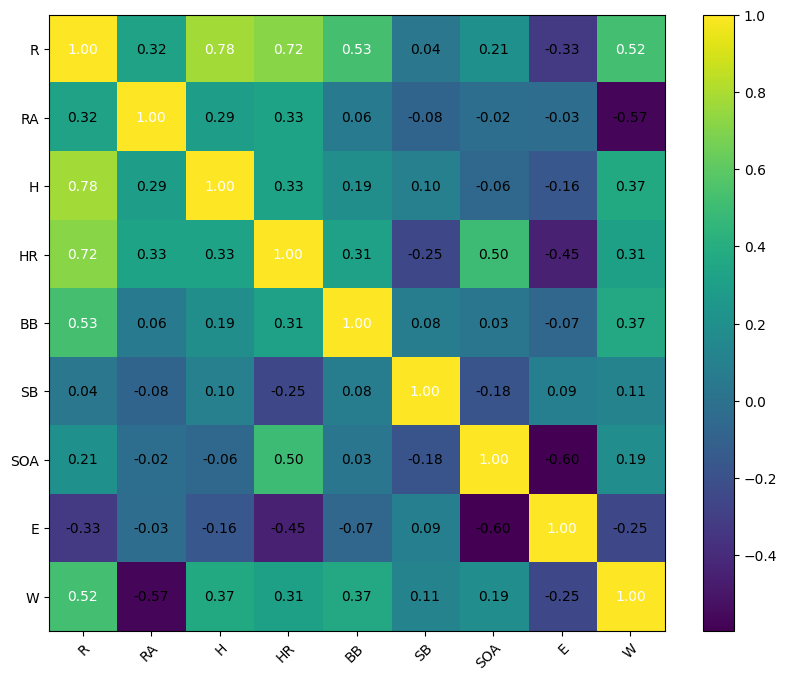

In [7]:
cm = np.corrcoef(TEAMS_data[headers_list].values.T)
hm = heatmap(cm, row_names=headers_list, column_names=headers_list, figsize=(10, 8))
plt.show()

In [8]:
## Convert Pandas to Numpy
TEAMS_np = TEAMS_data.to_numpy()
X = TEAMS_np[:, :-1]
y = TEAMS_np[:, 8:9]
print(X.shape)
print(y.shape)

(1460, 8)
(1460, 1)


In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(1168, 8) (292, 8) (1168, 1) (292, 1)


In [10]:
## fix data type
X_train = X_train.astype(np.float32)
X_test  = X_test.astype(np.float32)
y_train = y_train.astype(np.float32)
y_test  = y_test.astype(np.float32)

X_train_tr = torch.from_numpy(X_train)
X_test_tr  = torch.from_numpy(X_test)
y_train_tr = torch.from_numpy(y_train)
y_test_tr  = torch.from_numpy(y_test)

In [11]:
## standardization values from the training set (used inside the models)
x_means      = X_train_tr.mean(0, keepdim=True)
x_deviations = X_train_tr.std(0, keepdim=True) + epsilon

In [12]:
train_ds = TensorDataset(X_train_tr, y_train_tr)
train_dl = DataLoader(train_ds, batch_size, shuffle=True)

In [13]:
## Linear Regression
class LinRegNet(nn.Module):
    def __init__(self, x_means, x_deviations):
        super().__init__()
        self.x_means      = x_means
        self.x_deviations = x_deviations
        self.linear1 = nn.Linear(8, 1)

    def forward(self, x):
        x = (x - self.x_means) / self.x_deviations
        y_pred = self.linear1(x)
        return y_pred

In [14]:
## MLP
class MLP_Net(nn.Module):
    def __init__(self, x_means, x_deviations):
        super().__init__()
        self.x_means      = x_means
        self.x_deviations = x_deviations
        self.linear1 = nn.Linear(8, 16)
        self.act1    = nn.Sigmoid()
        self.linear2 = nn.Linear(16, 1)

    def forward(self, x):
        x = (x - self.x_means) / self.x_deviations
        x = self.linear1(x)
        x = self.act1(x)
        y_pred = self.linear2(x)
        return y_pred

In [15]:
## Deep Learning with 2 hidden layers
class DL_Net(nn.Module):
    def __init__(self, x_means, x_deviations):
        super().__init__()
        self.x_means      = x_means
        self.x_deviations = x_deviations
        self.linear1 = nn.Linear(8, 32)
        self.act1    = nn.ReLU()
        self.linear2 = nn.Linear(32, 16)
        self.act2    = nn.ReLU()
        self.linear3 = nn.Linear(16, 1)

    def forward(self, x):
        x = (x - self.x_means) / self.x_deviations
        x = self.linear1(x)
        x = self.act1(x)
        x = self.linear2(x)
        x = self.act2(x)
        y_pred = self.linear3(x)
        return y_pred

In [16]:
## Linear plus Nonlinear: f1 + f2
class LinearPlusNonLinear_Net(nn.Module):
    def __init__(self, x_means, x_deviations):
        super().__init__()
        self.x_means      = x_means
        self.x_deviations = x_deviations
        ## F1
        self.f1_linear1 = nn.Linear(8, 1)
        ## F2
        self.f2_linear1 = nn.Linear(8, 16)
        self.f2_act1    = nn.Sigmoid()
        self.f2_linear2 = nn.Linear(16, 1)

    def forward(self, x):
        x = (x - self.x_means) / self.x_deviations
        ## F1
        f1 = self.f1_linear1(x)
        ## F2
        f2 = self.f2_linear1(x)
        f2 = self.f2_act1(f2)
        f2 = self.f2_linear2(f2)
        y_pred = f1 + f2
        return y_pred

In [17]:
def training_loop(N_Epochs, model, loss_fn, opt):
    for epoch in range(N_Epochs):
        for xb, yb in train_dl:
            y_pred = model(xb)
            loss   = loss_fn(y_pred, yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
        if epoch % 50 == 0:
            print(epoch, "loss=", loss.item())

In [18]:
models = {
    "LinReg":           LinRegNet(x_means, x_deviations),
    "MLP":              MLP_Net(x_means, x_deviations),
    "DL (2 hidden)":    DL_Net(x_means, x_deviations),
    "Linear+NonLinear": LinearPlusNonLinear_Net(x_means, x_deviations),
}

results = {}
for name, model in models.items():
    print("Training", name)
    opt = torch.optim.Adam(model.parameters(), lr=learning_rate)
    training_loop(N_Epochs, model, F.mse_loss, opt)
    y_pred_test = model(X_test_tr)
    results[name] = r2_score(y_test_tr.numpy(), y_pred_test.detach().numpy())
    print("Testing R**2:", results[name])

Training LinReg
0 loss= 6909.0859375
50 loss= 2071.5693359375
100 loss= 352.9067687988281
150 loss= 7.803631782531738
200 loss= 24.53913688659668
250 loss= 18.784048080444336
Testing R**2: 0.8997020125389099
Training MLP
0 loss= 5374.75390625
50 loss= 27.652795791625977
100 loss= 11.246360778808594
150 loss= 17.569944381713867
200 loss= 10.509424209594727
250 loss= 14.202719688415527
Testing R**2: 0.8881089091300964
Training DL (2 hidden)
0 loss= 418.7197570800781
50 loss= 10.801424026489258
100 loss= 24.001399993896484
150 loss= 30.139873504638672
200 loss= 10.251154899597168
250 loss= 20.918394088745117
Testing R**2: 0.875615119934082
Training Linear+NonLinear
0 loss= 6069.431640625
50 loss= 15.045732498168945
100 loss= 24.910762786865234
150 loss= 11.09063720703125
200 loss= 12.279288291931152
250 loss= 16.258893966674805
Testing R**2: 0.8998422026634216


In [19]:
regressor = xgb.XGBRegressor(n_estimators=100, reg_lambda=1, gamma=0, max_depth=3)
regressor.fit(X_train, y_train)
y_pred = regressor.predict(X_test)
results["XGBoost"] = r2_score(y_test, y_pred)
print("XGBoost Testing R**2:", results["XGBoost"])

XGBoost Testing R**2: 0.8735366463661194


In [20]:
results_df = pd.DataFrame(list(results.items()), columns=["Model", "Test R2"]).sort_values("Test R2", ascending=False)
results_df

,Model,Test R2
3,Linear+NonLinear,0.899842
0,LinReg,0.899702
1,MLP,0.888109
2,DL (2 hidden),0.875615
4,XGBoost,0.873537


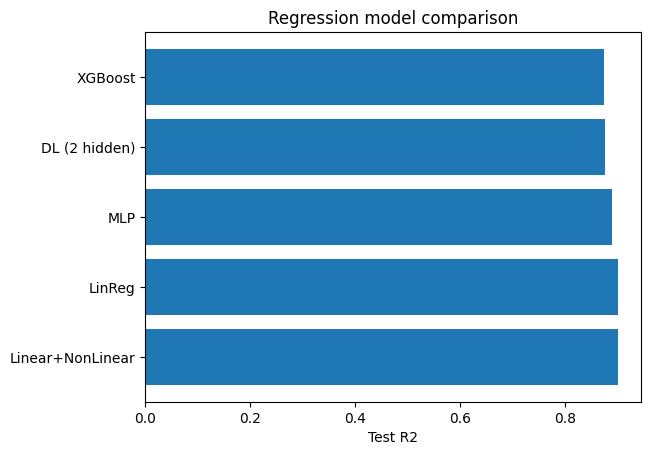

In [21]:
plt.barh(results_df["Model"], results_df["Test R2"])
plt.xlabel("Test R2")
plt.title("Regression model comparison")
plt.show()

Best PyTorch model: Linear+NonLinear


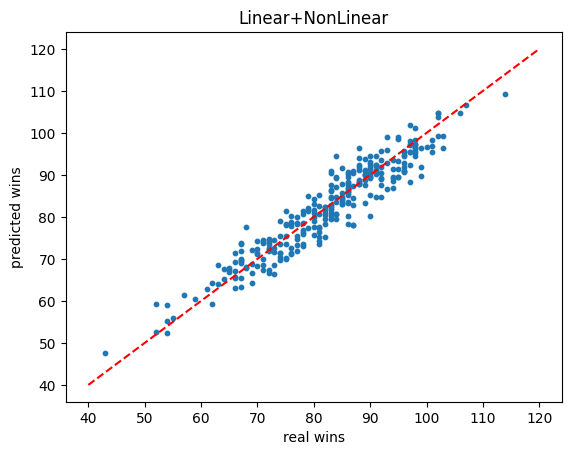

In [22]:
## best PyTorch model
best_name  = max(models, key=lambda n: results[n])
best_model = models[best_name]
print("Best PyTorch model:", best_name)

y_pred_test = best_model(X_test_tr).detach().numpy()
plt.scatter(y_test, y_pred_test, s=10)
plt.plot([40, 120], [40, 120], "r--")
plt.xlabel("real wins")
plt.ylabel("predicted wins")
plt.title(best_name)
plt.show()

In [23]:
for i in range(10):
    print("pred, real:", y_pred_test[i][0], y_test[i][0])

pred, real: 96.838554 101.0
pred, real: 86.15763 83.0
pred, real: 99.03129 95.0
pred, real: 85.225044 86.0
pred, real: 62.918095 61.0
pred, real: 92.23534 91.0
pred, real: 81.60289 82.0
pred, real: 89.42354 94.0
pred, real: 70.02568 71.0
pred, real: 59.231518 62.0


In [24]:
best_model.eval().float()
dummy_input = torch.randn(1, 8, dtype=torch.float32)

torch.onnx.export(
    best_model,
    dummy_input,
    "docs/wins_regression.onnx",
    input_names=["input1"],
    output_names=["output1"],
    opset_version=15,
    do_constant_folding=True,
    dynamo=False,
    dynamic_axes={"input1": {0: "batch"}, "output1": {0: "batch"}}
)
print("ONNX model saved")

ONNX model saved


/tmp/ipykernel_522/1078158599.py:4: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


In [25]:
## check the ONNX model gives the same R2
sess = rt.InferenceSession("docs/wins_regression.onnx")
pred_ort = sess.run(["output1"], {"input1": X_test})[0]
print("ONNX Testing R**2:", r2_score(y_test, pred_ort))

ONNX Testing R**2: 0.8998422026634216
